# MolGAN + Tox21 — parcours complet du projet

Ce notebook relie les étapes réellement implémentées : audit MoleculeNet Tox21, préparation et validation chimique des graphes, baseline MolGAN/WGAN-GP, classifieur indépendant d'activité d'essai NR-AR, génération et évaluation, puis comparaison REINFORCE de deux récompenses. Les longues opérations d'entraînement sont désactivées par défaut et nécessitent une action explicite dans les paramètres du notebook.

**Interprétation scientifique :** NR-AR est une activité de reporter assay *in vitro*. Une prédiction négative n'est pas une preuve d'innocuité; les sorties du modèle ne remplacent pas des validations expérimentales.

## 0. Environnement et kernel

Depuis la racine du dépôt, créez/activez l'environnement virtuel documenté dans le README. Pour installer la dépendance du kernel dans cet environnement, exécutez une fois :

```powershell
python -m pip install -e ".[notebook]"
python -m ipykernel install --user --name molgan-tox21 --display-name "Python (MolGAN Tox21)"
```

Puis sélectionnez **Python (MolGAN Tox21)** comme kernel dans VS Code. Le kernel s'exécute dans l'environnement du projet; aucune installation dans le Python global n'est requise.

In [1]:
from pathlib import Path
import json
import os
import sys
import subprocess

def find_project_root(start=None):
    candidate = Path(start or Path.cwd()).resolve()
    for path in (candidate, *candidate.parents):
        if (path / "pyproject.toml").is_file() and (path / "src").is_dir():
            return path
    raise FileNotFoundError("Impossible de localiser la racine du dépôt MolGAN/Tox21.")

ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import deepchem as dc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from rdkit import Chem, rdBase
from IPython.display import Image, display

print("Projet :", ROOT)
print("Python :", sys.version.split()[0], "| exécutable :", sys.executable)
print("DeepChem :", dc.__version__, "| PyTorch :", torch.__version__)
print("RDKit :", rdBase.rdkitVersion, "| CUDA disponible :", torch.cuda.is_available())

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


No normalization for NumAmideBonds. Feature removed!


No normalization for NumAtomStereoCenters. Feature removed!


No normalization for NumBridgeheadAtoms. Feature removed!


...

Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (C:\Users\bouac\.VIRTUALENVS\DJANGO-URL9J1GI\Lib\site-packages\deepchem\models\torch_models\__init__.py)


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'jax'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Projet : C:\Users\bouac\Desktop\python\web\molgan
Python : 3.11.2 | exécutable : C:\Users\bouac\.VIRTUALENVS\DJANGO-URL9J1GI\Scripts\python.exe
DeepChem : 2.8.0 | PyTorch : 2.14.1+cpu
RDKit : 2026.09.1 | CUDA disponible : False


## 1. Charger et auditer Tox21

Le loader DeepChem fournit les partitions MoleculeNet officielles. `w == 0` marque une mesure absente : les valeurs de remplissage de `y` ne sont pas des négatifs. Le test reste réservé à l'évaluation.

In [2]:
from src.data.tox21 import load_tox21_splits, write_tox21_audit

splits = load_tox21_splits()
audit = write_tox21_audit(splits)
split_sizes = pd.Series({name: len(dataset) for name, dataset in zip(("train", "validation", "test"), splits.datasets)}, name="composés")
print("Tâches :", ", ".join(splits.tasks))
print("Featurizer/split/transformers :", audit["featurizer"], audit["splitter"], audit["transformers"])
print("IDs de dataset sont des SMILES :", audit["ids"]["contains_smiles"])
print("Rapport d'audit :", ROOT / "data/audit/tox21_molnet_audit.json")
display(split_sizes.to_frame())

label_rows = []
for split_name, split_report in audit["splits"].items():
    for task, counts in split_report["tasks"].items():
        label_rows.append({"split": split_name, "endpoint": task, **counts})
label_audit = pd.DataFrame(label_rows)
display(label_audit.pivot(index="endpoint", columns="split", values=["positive", "negative", "missing"]))

Tâches : NR-AR, NR-AR-LBD, NR-AhR, NR-Aromatase, NR-ER, NR-ER-LBD, NR-PPAR-gamma, SR-ARE, SR-ATAD5, SR-HSE, SR-MMP, SR-p53
Featurizer/split/transformers : GraphConv scaffold []
IDs de dataset sont des SMILES : True
Rapport d'audit : C:\Users\bouac\Desktop\python\web\molgan\data\audit\tox21_molnet_audit.json


,composés
train,6258
validation,782
test,783


positive                  negative                  missing  \
split             test train validation     test train validation    test   
endpoint                                                                    
NR-AR               27   250         31      688  5570        692      68   
NR-AR-LBD           19   193         25      605  5307        602     159   
NR-AhR              92   589         87      537  4705        532     154   
NR-Aromatase        47   208         45      476  4575        464     260   
NR-ER               70   646         75      484  4432        479     229   
NR-ER-LBD           21   299         29      632  5332        635     130   
NR-PPAR-gamma       22   132         32      553  5160        544     208   
SR-ARE             118   718        106      363  4153        367     302   
SR-ATAD5            33   196         35      639  5533        629     111   
SR-HSE              47   281         44      525  5033        530     211   
SR-MMP              96   711        111      424  4065        397     263   
SR-p53              72   276         75      558  5213        573     153   

                                
split         train validation  
endpoint                        
NR-AR           438         59  
NR-AR-LBD       758        155  
NR-AhR          964        163  
NR-Aromatase   1475        273  
NR-ER          1180        228  
NR-ER-LBD       627        118  
NR-PPAR-gamma   966        206  
SR-ARE         1387        309  
SR-ATAD5        529        118  
SR-HSE          944        208  
SR-MMP         1482        274  
SR-p53          769        134

## 2. Préparer les graphes et contrôler les reconstructions RDKit

La représentation MolGAN est limitée à 9 sommets et aux atomes C/N/O/F neutres (plus le padding). Les dimensions de tenseur ne garantissent pas la validité chimique : les molécules reconstruites sont explicitement sanitizées.

Entrées / graphes acceptés / rejets : 30 8 22
Résumé reconstruction : {'input_graph_count': 8, 'tensor_valid_count': 8, 'rdkit_conversion_count': 8, 'sanitized_molecule_count': 8, 'ignored_padding_edge_count': 0, 'tensor_valid_rate': 1.0, 'rdkit_conversion_rate': 1.0, 'sanitization_rate_after_conversion': 1.0, 'overall_survival_rate': 1.0, 'failures': []}


,input_smiles,canonical_after_round_trip,same_structure
0,C#CCO,C#CCO,True
1,CC(O)CC(C)(C)O,CC(O)CC(C)(C)O,True
2,CC(C)(C)CC(C)(C)N,CC(C)(C)CC(C)(C)N,True
3,CC(=O)CC(C)C,CC(=O)CC(C)C,True
4,CCCC(C)=O,CCCC(C)=O,True
5,CC(=O)CCC(C)=O,CC(=O)CCC(C)=O,True
6,N#CCCNCCC#N,N#CCCNCCC#N,True
7,CCCCCC(C)O,CCCCCC(C)O,True


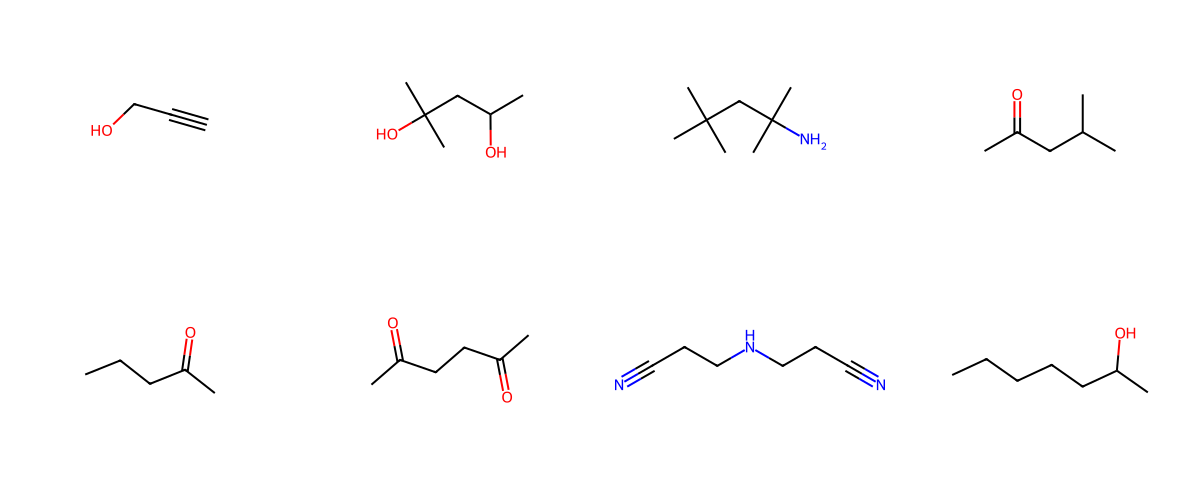

In [3]:
from src.data.molgan_graphs import featurize_smiles, reconstruct_graphs
from src.visualization.molecules import save_molecule_grid

graph_demo = featurize_smiles((str(smiles) for smiles in splits.train.ids[:30]), max_atom_count=9)
round_trip = reconstruct_graphs(graph_demo.graphs, graph_demo.featurizer)
print("Entrées / graphes acceptés / rejets :", graph_demo.input_count, len(graph_demo.graphs), len(graph_demo.rejections))
print("Résumé reconstruction :", round_trip.summary())
round_trip_rows = pd.DataFrame([
    {"input_smiles": original, "canonical_after_round_trip": reconstructed, "same_structure": original == reconstructed}
    for original, reconstructed in zip(graph_demo.canonical_smiles, round_trip.canonical_smiles)
])
display(round_trip_rows.head(10))
valid_demo_molecules = [molecule for molecule in round_trip.molecules if molecule is not None]
if valid_demo_molecules:
    graph_image = save_molecule_grid(valid_demo_molecules[:12], ROOT / "artifacts/molgan_notebook_graph_demo.png")
    display(Image(filename=str(graph_image)))
else:
    print("Aucune molécule valide dans cet échantillon de démonstration.")

## 3. Baseline génératif MolGAN/WGAN-GP

Le baseline conserve les pertes natives de DeepChem (critique Wasserstein avec pénalité de gradient). Entraînement complet et smoke test sont opt-in afin d'éviter une longue exécution CPU accidentelle. Après entraînement, le notebook lit les métriques réellement enregistrées; une baisse des pertes ne signifie pas à elle seule une génération chimiquement valide.

,epoch,global_step,training_graph_count,device,seed,property_reward,generator_loss_mean,discriminator_loss_mean,generated_graph_count,decoded_and_sanitized_count,validity_rate,unique_valid_count,uniqueness_rate,novel_valid_count,novelty_rate,reconstruction
95,96,2016,671,cpu,42,None,-13.014740,-0.231014,64,0,0.0,0,0.0,0,0.0,"{'input_graph_count': 64, 'tensor_valid_count'..."
96,97,2037,671,cpu,42,None,-12.979977,-0.264575,64,0,0.0,0,0.0,0,0.0,"{'input_graph_count': 64, 'tensor_valid_count'..."
97,98,2058,671,cpu,42,None,-12.949474,-0.288612,64,0,0.0,0,0.0,0,0.0,"{'input_graph_count': 64, 'tensor_valid_count'..."
98,99,2079,671,cpu,42,None,-12.905435,-0.332668,64,0,0.0,0,0.0,0,0.0,"{'input_graph_count': 64, 'tensor_valid_count'..."
99,100,2100,671,cpu,42,None,-12.850559,-0.371055,64,0,0.0,0,0.0,0,0.0,"{'input_graph_count': 64, 'tensor_valid_count'..."


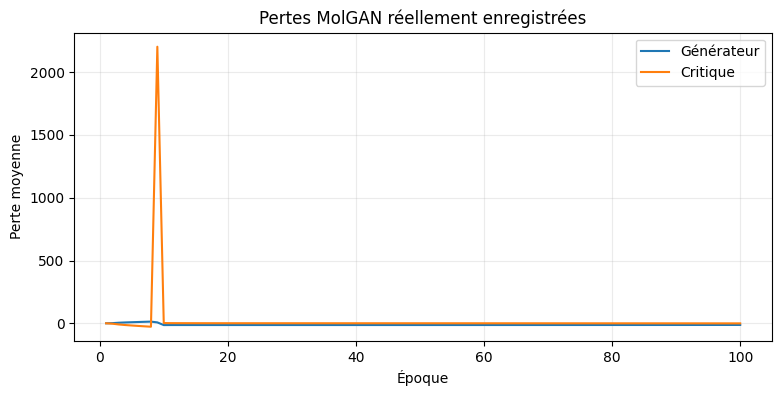

,epoch,generated_graph_count,decoded_and_sanitized_count,validity_rate,unique_valid_count
95,96,64,0,0.0,0
96,97,64,0,0.0,0
97,98,64,0,0.0,0
98,99,64,0,0.0,0
99,100,64,0,0.0,0


In [4]:
RUN_BASELINE_SMOKE = False
RUN_FULL_BASELINE = False
if RUN_BASELINE_SMOKE and RUN_FULL_BASELINE:
    raise ValueError("Choisissez le smoke test ou l'entraînement complet, pas les deux.")
if RUN_BASELINE_SMOKE:
    subprocess.run([sys.executable, "scripts/train_baseline.py", "--smoke-test", "--device", "cpu"], cwd=ROOT, check=True)
elif RUN_FULL_BASELINE:
    subprocess.run([sys.executable, "scripts/train_baseline.py"], cwd=ROOT, check=True)

baseline_dir = ROOT / "artifacts/molgan_baseline"
metrics_path = baseline_dir / "training_metrics.json"
if metrics_path.exists():
    baseline_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    epoch_metrics = pd.DataFrame(baseline_metrics["epochs"])
    display(epoch_metrics.tail())
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(epoch_metrics["epoch"], epoch_metrics["generator_loss_mean"], label="Générateur")
    ax.plot(epoch_metrics["epoch"], epoch_metrics["discriminator_loss_mean"], label="Critique")
    ax.set(xlabel="Époque", ylabel="Perte moyenne", title="Pertes MolGAN réellement enregistrées")
    ax.legend(); ax.grid(alpha=0.25); plt.show()
    display(epoch_metrics[["epoch", "generated_graph_count", "decoded_and_sanitized_count", "validity_rate", "unique_valid_count"]].tail())
else:
    print("Pas encore d'artefact baseline. Activez RUN_BASELINE_SMOKE ou RUN_FULL_BASELINE.")

## 4. Prédicteur supervisé NR-AR indépendant

La forêt aléatoire utilise des empreintes Morgan et les labels observés seulement. Le train sert à l'ajustement, validation à la sélection; le test n'est utilisé que par le script d'évaluation dédié. Le résultat représente une activité prédite dans l'essai NR-AR, pas une preuve de toxicité ni de sécurité.

In [5]:
TRAIN_NR_AR_PREDICTOR = False
EVALUATE_NR_AR_TEST = False
if TRAIN_NR_AR_PREDICTOR:
    subprocess.run([sys.executable, "scripts/train_tox21_predictor.py", "--endpoint", "NR-AR"], cwd=ROOT, check=True)
predictor_dir = ROOT / "artifacts/tox21_predictors/nr_ar"
predictor_path = predictor_dir / "predictor.joblib"
if EVALUATE_NR_AR_TEST:
    if not predictor_path.exists():
        raise FileNotFoundError("Entraînez d'abord le prédicteur NR-AR.")
    subprocess.run([sys.executable, "scripts/evaluate_tox21_predictor.py", "--endpoint", "NR-AR"], cwd=ROOT, check=True)
if predictor_path.exists():
    from src.models.tox21_endpoint import Tox21EndpointPredictor
    predictor = Tox21EndpointPredictor.load(predictor_path)
    example_molecules = [Chem.MolFromSmiles(smiles) for smiles in ["CCO", "c1ccccc1", "CC(=O)O"]]
    display(pd.DataFrame(predictor.predict(example_molecules)))
    test_report_path = predictor_dir / "test_evaluation.json"
    if test_report_path.exists():
        test_report = json.loads(test_report_path.read_text(encoding="utf-8"))
        print("Évaluation test sauvegardée; labels observés :", test_report["sample_count"], "| classes :", test_report["class_counts"])
        display(pd.Series(test_report["metrics"], name="test metrics").to_frame())
    else:
        print("Rapport test absent. Activez EVALUATE_NR_AR_TEST pour lancer l'évaluation réservée au test.")
else:
    print("Prédicteur absent. Activez TRAIN_NR_AR_PREDICTOR pour l'entraîner sur train et sélectionner sur validation.")

,endpoint,outcome_label,predicted_probability_active,predicted_assay_active,decision_threshold,interpretation
0,NR-AR,predicted Tox21 assay activity,0.004474,False,0.349454,Androgen receptor (AR) pathway reporter-assay ...
1,NR-AR,predicted Tox21 assay activity,0.028392,False,0.349454,Androgen receptor (AR) pathway reporter-assay ...
2,NR-AR,predicted Tox21 assay activity,0.012965,False,0.349454,Androgen receptor (AR) pathway reporter-assay ...


Évaluation test sauvegardée; labels observés : 715 | classes : {'negative': 688, 'positive': 27}


,test metrics
roc_auc,0.730082
average_precision,0.443389
accuracy,0.956643
balanced_accuracy,0.710594
precision,0.428571
recall_sensitivity,0.444444
specificity,0.976744
f1,0.436364
brier_score,0.045881
expected_calibration_error,0.125267


## 5. Générer, décoder et évaluer les graphes du checkpoint

Cette cellule charge les poids du baseline sauvegardé, génère des graphes puis vérifie leur décodage et leur sanitation RDKit. La nouveauté est calculée par rapport aux seules structures train. Aucun résultat n'est inventé si le générateur ne fournit pas de molécule valide.

In [6]:
from src.models.molgan import build_model, generate_graphs, load_generator, resolve_device, seed_everything
from src.data.tox21 import TASKS

generation_count = 64
generator_path = baseline_dir / "generator_weights.pt"
if generator_path.exists():
    config = json.loads((ROOT / "configs/default.json").read_text(encoding="utf-8"))
    valid_training = featurize_smiles((str(smiles) for smiles in splits.train.ids), max_atom_count=config["molgan"]["vertices"])
    seed_everything(int(config["seed"]))
    molgan = build_model(config, seed=int(config["seed"]), device="cpu")
    load_generator(molgan, generator_path)
    generated_graphs = generate_graphs(molgan, generation_count)
    generated = reconstruct_graphs(generated_graphs, valid_training.featurizer)
    valid_smiles = [value for value in generated.canonical_smiles if value is not None]
    unique_smiles = set(valid_smiles)
    training_smiles = set(valid_training.canonical_smiles)
    generation_summary = {
        "generated_graphs": len(generated_graphs),
        "RDKit_valid": generated.sanitized_count,
        "validity_rate": generated.sanitized_count / len(generated_graphs) if generated_graphs else 0.0,
        "unique_valid": len(unique_smiles),
        "novel_unique": len(unique_smiles - training_smiles),
        "reconstruction": generated.summary(),
    }
    display(pd.Series({key: value for key, value in generation_summary.items() if key != "reconstruction"}).to_frame("observed"))
    if generated.sanitized_count:
        generated_image = save_molecule_grid([m for m in generated.molecules if m is not None][:16], ROOT / "artifacts/molgan_notebook_generated.png")
        display(Image(filename=str(generated_image)))
    else:
        print("Aucune molécule valide à dessiner; consultez les causes d'échec ci-dessous.")
    display(pd.DataFrame(generated.summary()["failures"]).head(10))
else:
    print("Checkpoint générateur absent. Exécutez d'abord un entraînement baseline.")

Generating 64 samples


,observed
generated_graphs,64.0
RDKit_valid,0.0
validity_rate,0.0
unique_valid,0.0
novel_unique,0.0


Aucune molécule valide à dessiner; consultez les causes d'échec ci-dessous.


,graph_index,stage,reason,detail
0,0,validation,self_bond,Les boucles de liaison sont interdites.
1,1,validation,self_bond,Les boucles de liaison sont interdites.
2,2,validation,self_bond,Les boucles de liaison sont interdites.
3,3,validation,self_bond,Les boucles de liaison sont interdites.
4,4,validation,self_bond,Les boucles de liaison sont interdites.
5,5,validation,self_bond,Les boucles de liaison sont interdites.
6,6,validation,self_bond,Les boucles de liaison sont interdites.
7,7,validation,self_bond,Les boucles de liaison sont interdites.
8,8,validation,self_bond,Les boucles de liaison sont interdites.
9,9,validation,self_bond,Les boucles de liaison sont interdites.


## 6. Comparaison des récompenses guidées NR-AR

Le fine-tuning utilise REINFORCE sur les catégories atomiques et de liaisons échantillonnées; il met à jour le générateur mais pas le critique WGAN. La cible est uniquement l'activité prédite dans l'essai NR-AR. Validité, diversité, similarité au train et désaccord de la forêt modulent la récompense. Les scores sont des heuristiques computationnelles, pas des résultats expérimentaux.

,bras,graphes,valides,taux_validité,uniques,activité prédite moyenne,activité au seuil,hors domaine
0,baseline,8,0,0.0,0,None,None,0.0
1,activity_focused,8,0,0.0,0,None,None,0.0
2,balanced,8,0,0.0,0,None,None,0.0


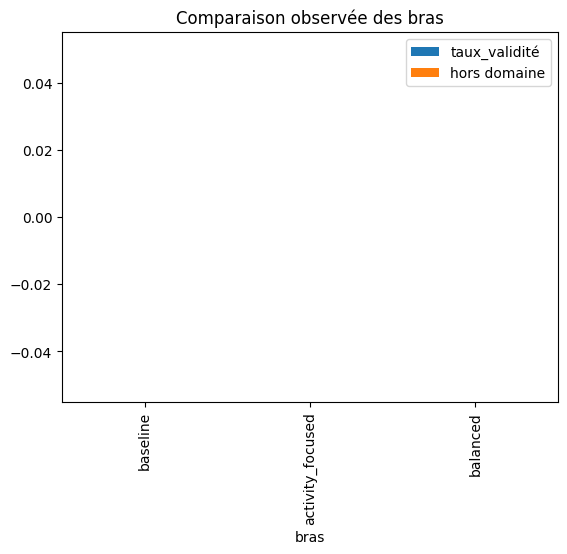

Interprétation limitée : All generated-sample outcomes are computational predictions, not experimental toxicology results.


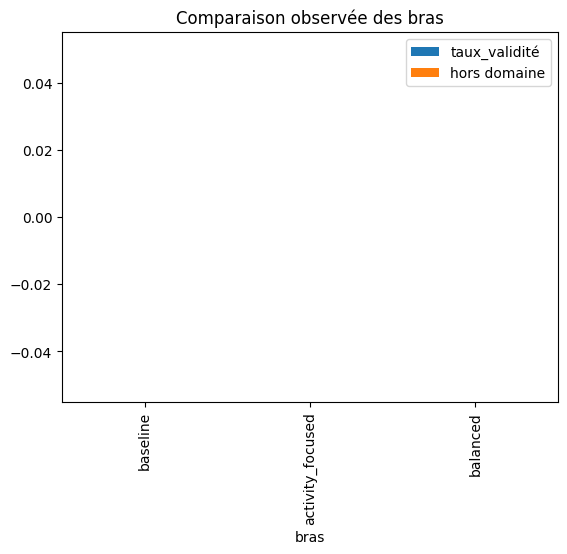

In [7]:
RUN_GUIDED_COMPARISON = False
if RUN_GUIDED_COMPARISON:
    if not generator_path.exists() or not predictor_path.exists():
        raise FileNotFoundError("Il faut un checkpoint baseline et un prédicteur NR-AR sauvegardé.")
    subprocess.run([sys.executable, "scripts/compare_tox21_rewards.py", "--device", "cpu"], cwd=ROOT, check=True)
comparison_path = ROOT / "artifacts/tox21_guided_nr_ar/comparison.json"
if comparison_path.exists():
    comparison = json.loads(comparison_path.read_text(encoding="utf-8"))
    comparison_table = pd.DataFrame([
        {"bras": arm["arm"], "graphes": arm["generated_graph_count"], "valides": arm["rdkit_valid_count"], "taux_validité": arm["validity_rate"], "uniques": arm["unique_valid_count"], "activité prédite moyenne": arm["unique_sample_activity_probability_mean"], "activité au seuil": arm["unique_sample_predicted_active_rate"], "hors domaine": arm["out_of_domain_valid_rate"]}
        for arm in comparison["arms"]
    ])
    display(comparison_table)
    if comparison_table["taux_validité"].notna().any():
        display(comparison_table.set_index("bras")[["taux_validité", "hors domaine"]].plot.bar(title="Comparaison observée des bras").figure)
    print("Interprétation limitée :", comparison["interpretation_limitation"])
else:
    print("Rapport de comparaison absent. Activez RUN_GUIDED_COMPARISON après avoir entraîné baseline et prédicteur.")

## 7. Reproductibilité, tests et limites

Seed et hyperparamètres sont dans `configs/default.json`; caches Tox21 et artefacts modèles/rapports sont locaux et ignorés par Git. Les splits d'origine restent inchangés. Les poids pré-entraînés ne sont pas requis pour exécuter le notebook, mais la comparaison guidée nécessite les deux artefacts sauvegardés.

Limites à garder en tête : l'espace des graphes est restreint à 9 atomes et C/N/O/F; le test NR-AR ne compte que 27 positifs; l'incertitude entre arbres est un proxy non calibré; un bon score prédit ne démontre ni innocuité ni toxicité en conditions réelles. Toute hypothèse de bénéfice requiert une génération chimiquement valide, diversité suffisante, évaluation hors domaine et validation expérimentale.

In [8]:
RUN_TEST_SUITE = False
if RUN_TEST_SUITE:
    subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, check=True)
else:
    print("Tests désactivés par défaut. Pour exécuter la suite complète, définissez RUN_TEST_SUITE = True et relancez cette cellule.")

Tests désactivés par défaut. Pour exécuter la suite complète, définissez RUN_TEST_SUITE = True et relancez cette cellule.
